# ChatPromptTemplate과 MessagesPlaceholder

**이 노트북에서 할 일**

1. 03절 예시 없음 목록을, 고객 문의 자리만 비워 둔 메시지 틀로 만듭니다.
2. 틀을 채운 목록이 03절 목록과 같은지 확인하고, 같은 모델로 보냅니다.
3. 틀에 대화 기록 자리를 더해, 기록 없음·기록 있음·최근 메시지 하나만 넣은 목록을 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.

인터넷 서비스에 요청을 모두 4번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**강의와 실습 범위** — 강의 시간에는 3~6절(틀 만들기·채우기·보내기, 대화 기록 자리)을 설명합니다.
7·8절(기록 없음과 기록 있음 보내기, 값 바꿔 보기)은 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.10.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch07-prompt-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

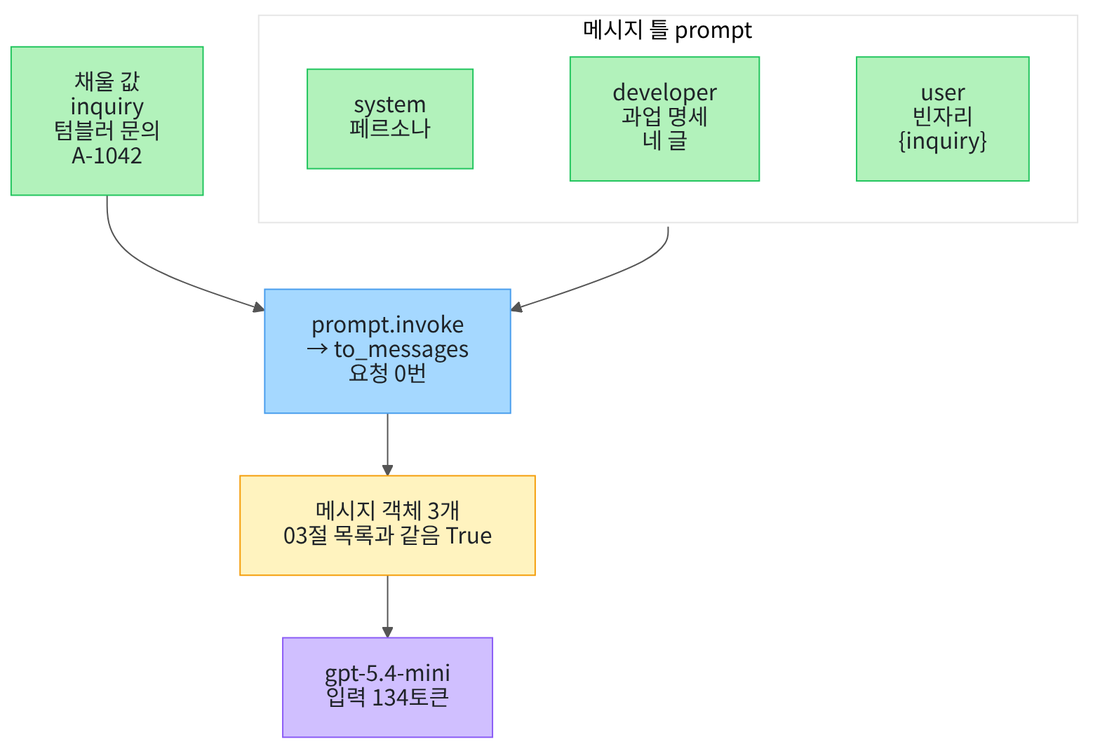

위에서 아래로 읽습니다. 큰 상자는 이 노트북 3절에서 만드는 메시지 틀이고, 셋째 메시지 자리만 비어 있습니다.
파란 상자에서 틀에 고객 문의를 채우면 메시지 객체 세 개가 나옵니다. 이 단계는 요청을 보내지 않습니다.

그 목록을 모델로 보낼 때 요청이 한 번 나갑니다. 6절부터는 틀에 대화 기록 자리를 하나 더 둡니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01~03절과 같은 실습 폴더와 같은 판입니다. 노트북은 앞 절 없이 새 커널에서 시작하므로 다시 확인합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `langchain-openai: 1.6.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다. 이 절의 틀 클래스는 langchain-core 패키지에 들어 있습니다.

걸린 시간을 재는 모듈 `time`(Ch 6 05절)과 모델 객체를 만드는 함수를 불러옵니다.

In [2]:
# 시간을 재는 모듈과 모델 객체를 만드는 함수를 불러옵니다
import time

from langchain.chat_models import init_chat_model

01~03절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01~03절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 03절 예시 없음 목록 다시 만들기

03절 예시 없음 목록은 system 페르소나, developer 과업 명세, user 고객 문의 세 메시지였습니다.
이 절은 그 목록을 틀로 옮깁니다. 그래서 먼저 03절과 글자까지 같은 목록을 다시 만듭니다.
03절처럼 만들면 고객 문의가 바뀔 때마다 이 셀 전체를 다시 써야 합니다. 이 불편을 틀로 줄여 봅니다.

In [5]:
# 03절과 같은 페르소나 글·고객 문의·과업 명세로 예시 없음 목록을 만듭니다
persona_text = "당신은 친절한 고객 상담원입니다."
inquiry_text = "어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다."
goal_text = "고객 문의를 분류하고 필요한 다음 행동을 안내하세요."
required_text = "회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요."
forbidden_text = "근거 없는 보상은 약속하지 마세요."
format_text = "분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요."
task_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n" + format_text
zero_messages = [("system", persona_text), ("developer", task_text), ("user", inquiry_text)]
print("고객 문의:", inquiry_text)
print("과업 명세:")
print(task_text)
print("예시 없음 목록의 메시지 수:", len(zero_messages))

고객 문의: 어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다.
과업 명세:
고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.
근거 없는 보상은 약속하지 마세요.
분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.
예시 없음 목록의 메시지 수: 3


**결과 읽기** — 첫 줄은 `고객 문의:`로 시작하고 `주문번호는 A-1042입니다.`가 들어 있습니다.
라벨 줄 `과업 명세:` 아래 네 줄은 03절과 같은 과업 명세입니다. 마지막 줄은 `예시 없음 목록의 메시지 수: 3`입니다.

## 3. 고객 문의 자리를 비워 둔 틀 만들기

메시지 틀(prompt template)은 바뀌지 않는 메시지는 그대로 적고, 바뀌는 자리만 비워 둔 메시지 목록입니다.
인사말이 인쇄돼 있고 받는 사람 이름 자리만 빈 생일 카드와 비슷합니다. 카드는 한 번 사 두고 이름만 적어 씁니다.
LangChain에서 채팅 메시지 틀을 만드는 클래스가 `ChatPromptTemplate`입니다. 메서드 `from_messages()`가 메시지 목록을 받아 틀 객체를 반환합니다.

비워 둘 자리는 글 `"{inquiry}"`처럼 이름을 중괄호로 감싸 적습니다.
Ch 2에서 본 f-string은 글 앞에 f를 붙여, 그 줄에서 바로 값을 넣었습니다. 이 글에는 f가 없어 Python은 그대로 두고, 틀이 나중에 값을 넣습니다.

먼저 03절 목록 모양 그대로 튜플 세 개를 넘겨 봅니다. 실행 전에 예상합니다. 01절 튜플 역할 developer도 받아 줄까요?
틀 만들기는 요청을 보내지 않습니다. 오류가 나면 받아서 종류와 메시지를 출력합니다.

In [6]:
# 03절 목록 모양 그대로 developer 튜플을 넣어 틀을 만들어 봅니다(요청은 보내지 않습니다)
from langchain_core.prompts import ChatPromptTemplate

tuple_parts = [("system", persona_text), ("developer", task_text), ("user", "{inquiry}")]
try:
    ChatPromptTemplate.from_messages(tuple_parts)
except ValueError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:")
    print(error)

오류 종류: ValueError
오류 메시지:
Unexpected message type: developer. Use one of 'human', 'user', 'ai', 'assistant', or 'system'.


**결과 읽기** — 첫 줄은 `오류 종류: ValueError`입니다. 라벨 줄 `오류 메시지:` 아래 줄은 `Unexpected message type: developer.`로 시작합니다.
뒤이어 `Use one of 'human', 'user', 'ai', 'assistant', or 'system'.`이 있습니다. 오류 메시지가 안내하는 역할 이름은 이 다섯 가지이고, developer는 없습니다.

01절에서 `invoke()`는 developer 튜플을 받아 주었습니다. 요청 전에 함수 `convert_to_messages()`가 `SystemMessage`로 바꿔 주었기 때문입니다.
설치한 langchain-core 1.6.2의 틀은 튜플 대신 이미 만든 메시지 객체도 받습니다. 그래서 developer 튜플만 01절 함수로 먼저 객체로 바꿔 넣습니다.

메시지 객체로 넣은 글은 틀이 빈자리를 찾지 않고 글 그대로 씁니다. 속성 `input_variables`는 틀이 채워 달라는 이름 목록입니다.

In [7]:
# developer 튜플을 01절 함수로 메시지 객체로 바꾼 뒤, 고객 문의 자리만 비워 둔 틀을 만듭니다
from langchain_core.messages import convert_to_messages

developer_message = convert_to_messages([("developer", task_text)])[0]
template_parts = [("system", persona_text), developer_message, ("user", "{inquiry}")]
prompt = ChatPromptTemplate.from_messages(template_parts)
print("둘째 메시지 추가 정보:", developer_message.additional_kwargs)
print("틀 객체 종류:", type(prompt).__name__)
print("채울 이름:", prompt.input_variables)

둘째 메시지 추가 정보: {'__openai_role__': 'developer'}
틀 객체 종류: ChatPromptTemplate
채울 이름: ['inquiry']


**결과 읽기** — 첫 줄은 `둘째 메시지 추가 정보: {'__openai_role__': 'developer'}`입니다. 01절에서 본 OpenAI 역할 표시가 붙어 있습니다.
둘째 줄은 `틀 객체 종류: ChatPromptTemplate`, 셋째 줄은 `채울 이름: ['inquiry']`입니다.
틀에서 비어 있는 자리는 고객 문의 하나뿐입니다. 페르소나와 과업 명세는 틀 안에 고정됐습니다.

## 4. 틀에 고객 문의 채우기

틀 객체에도 메서드 `invoke()`가 있습니다. 모델 객체의 `invoke()`와 이름은 같지만, 틀의 `invoke()`는 빈자리를 채울 뿐 요청을 보내지 않습니다.
두 메서드는 점 앞의 객체가 틀인지 모델인지로 구분합니다. 채울 값은 빈자리 이름을 키로 한 딕셔너리로 넘깁니다.

틀의 `invoke()`가 반환하는 채운 값(`ChatPromptValue`)은 메시지를 담은 객체입니다. 메서드 `to_messages()`가 그 안의 메시지 객체 목록을 반환합니다.
실행 전에 예상합니다. 01절에서 본 것처럼 클래스는 `SystemMessage` 둘과 `HumanMessage` 하나일 것입니다.

In [8]:
# 틀에 고객 문의를 채워 메시지 객체 목록을 만듭니다(요청은 보내지 않습니다)
fill_values = {"inquiry": inquiry_text}
filled_prompt = prompt.invoke(fill_values)
print("채운 값 종류:", type(filled_prompt).__name__)
prompt_messages = filled_prompt.to_messages()
print("채운 메시지 객체(클래스 | 역할 이름 | 추가 정보):")
for message in prompt_messages:
    class_name = type(message).__name__
    print(class_name, "|", message.type, "|", message.additional_kwargs)
print("user 메시지 내용:", prompt_messages[2].content)

채운 값 종류: ChatPromptValue
채운 메시지 객체(클래스 | 역할 이름 | 추가 정보):
SystemMessage | system | {}
SystemMessage | system | {'__openai_role__': 'developer'}
HumanMessage | human | {}
user 메시지 내용: 어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다.


**결과 읽기** — 첫 줄은 `채운 값 종류: ChatPromptValue`입니다.
라벨 줄 아래 세 줄은 `SystemMessage | system | {}`, `SystemMessage | system | {'__openai_role__': 'developer'}`, `HumanMessage | human | {}`입니다.
마지막 줄 `user 메시지 내용:` 뒤에 고객 문의 글이 그대로 들어갔습니다. 역할 이름 user는 Ch 6 02절처럼 `human`으로 보입니다.

01절에서는 `invoke()`에 넘기는 튜플 목록을 `convert_to_messages()`가 요청 전에 메시지 객체로 바꿨습니다.
틀로 만든 목록이 그 결과와 같은지 봅니다. 메시지 객체 목록끼리 `==`는 순서대로 클래스와 담긴 값이 모두 같으면 `True`입니다.
같다면 모델은 03절과 같은 메시지를 받습니다.

In [9]:
# 틀로 만든 목록이 03절 튜플 목록을 바꾼 메시지 객체 목록과 같은지 확인합니다
zero_converted = convert_to_messages(zero_messages)
same_as_zero = prompt_messages == zero_converted
print("03절 목록을 바꾼 결과와 같은가:", same_as_zero)
assert same_as_zero

03절 목록을 바꾼 결과와 같은가: True


**결과 읽기** — 출력 줄은 `03절 목록을 바꾼 결과와 같은가: True`이고, `assert`도 통과했습니다.
튜플로 적은 03절 목록과, 틀에 값을 채운 목록은 요청 전에 같은 메시지 객체가 됩니다.

틀의 쓸모는 같은 틀에 다른 값을 채울 때 보입니다. 다른 고객 문의 하나를 채워 봅니다.
실행 전에 예상합니다. 앞 두 메시지는 그대로이고, user 메시지만 바뀔 것입니다. 이 셀도 요청을 보내지 않습니다.

In [10]:
# 같은 틀에 다른 고객 문의를 채워, 앞 두 메시지는 그대로이고 user 메시지만 바뀌는지 봅니다
other_inquiry = "배송받은 머그컵 손잡이가 부러졌습니다. 주문번호는 A-1107입니다."
other_messages = prompt.invoke({"inquiry": other_inquiry}).to_messages()
same_front = other_messages[0] == prompt_messages[0] and other_messages[1] == prompt_messages[1]
print("앞 두 메시지가 같은가:", same_front)
print("바꾼 user 메시지 내용:", other_messages[2].content)
assert same_front

앞 두 메시지가 같은가: True
바꾼 user 메시지 내용: 배송받은 머그컵 손잡이가 부러졌습니다. 주문번호는 A-1107입니다.


**결과 읽기** — 첫 줄은 `앞 두 메시지가 같은가: True`입니다.
둘째 줄은 `바꾼 user 메시지 내용: 배송받은 머그컵 손잡이가 부러졌습니다. 주문번호는 A-1107입니다.`입니다.
페르소나와 과업 명세를 다시 쓰지 않고 고객 문의만 바꿨습니다. 머그컵 목록은 모델로 보내지 않습니다.

## 5. 틀로 만든 목록 보내기

01~03절과 같은 함수 두 개로 요청마다 기록 한 줄을 만듭니다. 먼저 `timed_invoke()` 함수를 정의합니다.
Ch 6 06절과 같은 코드입니다. 요청을 보내면서 걸린 시간을 재고, 응답 객체와 걸린 초를 튜플로 반환합니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [11]:
# 모델 객체로 메시지 목록을 보내고, 응답 객체와 걸린 초를 튜플로 반환하는 함수를 정의합니다
def timed_invoke(run_model, input_messages):
    start_time = time.perf_counter()
    run_response = run_model.invoke(input_messages)
    run_elapsed = time.perf_counter() - start_time
    return run_response, run_elapsed

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

둘째 함수 `make_prompt_record()`는 01~03절과 같은 코드입니다. 조건 이름·응답 객체·걸린 초로 딕셔너리 한 줄을 만듭니다.
키는 `조건`·`답`·`입력 토큰 수`·`출력 토큰 수`·`끝난 이유`·`걸린 초` 여섯 개입니다.
이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [12]:
# 조건 이름·응답 객체·걸린 초로 기록 한 줄(딕셔너리)을 만드는 함수를 정의합니다
def make_prompt_record(condition, run_response, run_elapsed):
    run_usage = run_response.usage_metadata
    record = {
        "조건": condition,
        "답": run_response.text,
        "입력 토큰 수": run_usage["input_tokens"],
        "출력 토큰 수": run_usage["output_tokens"],
        "끝난 이유": run_response.response_metadata["finish_reason"],
        "걸린 초": round(run_elapsed, 2),
    }
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 이제 틀로 만든 목록을 보냅니다.

모델 객체의 `invoke()`는 `timed_invoke()` 안에서 불립니다. 요청은 여기서 처음 나갑니다.
실행 전에 예상합니다. 메시지가 03절 목록과 같으므로 입력 토큰 수도 03절 예시 없음과 같은 134일 것입니다.

In [13]:
# 틀로 만든 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
template_response, template_elapsed = timed_invoke(model, prompt_messages)
template_record = make_prompt_record("틀로 만든 목록", template_response, template_elapsed)
print("답:")
print(template_record["답"])
print("입력 토큰 수:", template_record["입력 토큰 수"])

답:
분류: 교환 요청(파손)
다음 행동: 파손 사진을 보내주시면 교환 접수를 도와드리겠습니다. 주문번호 A-1042 확인했습니다.
고객에게 보낼 한 문장: 어제 받으신 텀블러 뚜껑 파손 건은 교환 접수를 위해 파손 사진을 보내주시면 바로 도와드리겠습니다.
입력 토큰 수: 134


**결과 읽기** — 라벨 줄 아래 세 줄은 `분류: 교환 요청(파손)`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
다음 행동 줄에 `주문번호 A-1042 확인했습니다.`가 있고, 두 줄에 사진 요청이 있습니다. 보상 약속은 없었습니다.
마지막 줄은 `입력 토큰 수: 134`입니다. 03절 예시 없음 목록의 입력 토큰 수 134와 같습니다.

모델이 받은 메시지가 같아 입력 토큰 수도 같았습니다. 답 첫 줄은 03절 예시 없음 답 「분류: 파손으로 인한 교환 문의」와 달랐습니다.
03절에서 본 것처럼 같은 목록도 실행마다 낱말이 달라질 수 있습니다. 이 답은 6절에서 대화 기록의 둘째 메시지로 다시 씁니다.

## 6. 대화 기록이 들어갈 자리 만들기

고객이 5절 답을 받고 다음 질문을 보냈다고 합시다. 「사진은 어디로 보내면 되나요?」입니다.
이 질문 글에는 주문번호도, 무엇이 깨졌는지도 없습니다. 앞에서 주고받은 메시지가 함께 가야 이어진 대화가 됩니다.
Ch 6 01절에서도 앞 답을 목록에 넣지 않으면 이어진 대화가 아니라고 했습니다.

앞에서 주고받은 메시지 목록을 대화 기록(history)이라고 부릅니다. 기록은 메시지 한 개가 아니라 여러 개라 글 빈자리에 넣을 수 없습니다.
클래스 `MessagesPlaceholder`는 틀 안에 메시지 목록이 통째로 들어갈 자리를 만듭니다. 첫 인자 `"history"`가 그 자리의 이름입니다.

인자 `optional=True`는 이 자리를 비워 둬도 된다는 뜻입니다. 첫 질문처럼 기록이 없는 경우에도 같은 틀을 씁니다.
기록 자리는 developer 메시지와 user 메시지 사이에 둡니다. user 빈자리 이름은 다음 질문이라 `question`으로 정합니다.

In [14]:
# 대화 기록이 들어갈 자리를 developer와 user 사이에 둔 틀을 만듭니다(요청은 보내지 않습니다)
from langchain_core.prompts import MessagesPlaceholder

history_slot = MessagesPlaceholder("history", optional=True)
history_parts = [("system", persona_text), developer_message, history_slot, ("user", "{question}")]
history_prompt = ChatPromptTemplate.from_messages(history_parts)
print("채울 이름:", history_prompt.input_variables)
print("비워 둘 수 있는 이름:", history_prompt.optional_variables)

채울 이름: ['question']
비워 둘 수 있는 이름: ['history']


**결과 읽기** — 두 줄은 `채울 이름: ['question']`과 `비워 둘 수 있는 이름: ['history']`입니다.
틀이 꼭 채워 달라는 이름은 `question` 하나이고, `history`는 비워 둬도 되는 이름으로 따로 분류됐습니다.

이번에는 다음 질문과 대화 기록을 만듭니다. 기록은 5절에서 실제로 주고받은 두 메시지입니다.
첫째는 고객 문의 `("user", inquiry_text)`, 둘째는 5절 답 `("assistant", template_record["답"])`입니다.
역할 이름 assistant는 모델이 한 말이라는 뜻이고, OpenAI 요청에서 모델 답의 역할 이름입니다.
라이브러리 LangChain은 이 튜플을 Ch 6 01절 응답 객체와 같은 클래스인 `AIMessage`로 바꿉니다.

In [15]:
# 고객의 다음 질문과, 5절에서 주고받은 두 메시지로 대화 기록 목록을 만듭니다
followup_text = "사진은 어디로 보내면 되나요?"
history_messages = [("user", inquiry_text), ("assistant", template_record["답"])]
print("다음 질문:", followup_text)
print("대화 기록의 메시지 수:", len(history_messages))

다음 질문: 사진은 어디로 보내면 되나요?
대화 기록의 메시지 수: 2


**결과 읽기** — 두 줄은 `다음 질문: 사진은 어디로 보내면 되나요?`와 `대화 기록의 메시지 수: 2`입니다.
기록 목록의 둘째 메시지 내용은 5절에서 받은 답 글 그대로입니다.

같은 틀을 두 번 채웁니다. 한 번은 기록 없이 `question`만, 한 번은 `history`까지 넣습니다.
실행 전에 예상합니다. 기록 없음은 system·developer·user 세 개, 기록 있음은 그 사이에 두 개가 더해져 다섯 개일 것입니다.

In [16]:
# 같은 틀을 기록 없이 한 번, 기록을 넣어 한 번 채웁니다(요청은 보내지 않습니다)
no_history_messages = history_prompt.invoke({"question": followup_text}).to_messages()
with_history_values = {"question": followup_text, "history": history_messages}
with_history_messages = history_prompt.invoke(with_history_values).to_messages()
print("기록 없음 메시지 수:", len(no_history_messages))
print("기록 있음 메시지 수:", len(with_history_messages))
print("기록 있음 메시지 객체(클래스 | 역할 이름):")
for message in with_history_messages:
    class_name = type(message).__name__
    print(class_name, "|", message.type)

기록 없음 메시지 수: 3
기록 있음 메시지 수: 5
기록 있음 메시지 객체(클래스 | 역할 이름):
SystemMessage | system
SystemMessage | system
HumanMessage | human
AIMessage | ai
HumanMessage | human


**결과 읽기** — 첫 두 줄은 `기록 없음 메시지 수: 3`과 `기록 있음 메시지 수: 5`입니다. 예상과 같습니다.
라벨 줄 아래 다섯 줄은 `SystemMessage | system` 두 줄, `HumanMessage | human`, `AIMessage | ai`, `HumanMessage | human`입니다.
기록의 두 메시지는 developer 메시지 뒤, 다음 질문 앞에 순서대로 들어갔습니다. 자리를 비워 두면 그 자리는 목록에서 빠집니다.

인자 `optional=True`를 빼면 어떻게 될까요? 기록 자리를 꼭 채워야 하는 틀을 만들고, 기록 없이 채워 봅니다.
실행 전에 예상합니다. 채울 이름에 `history`가 빠졌다는 오류가 날 것입니다. 이 셀도 요청을 보내지 않습니다.

In [17]:
# 기록 자리를 꼭 채워야 하는 틀을 만들고, 기록 없이 채워 봅니다(요청은 보내지 않습니다)
required_slot = MessagesPlaceholder("history")
required_parts = [("system", persona_text), developer_message, required_slot, ("user", "{question}")]
required_prompt = ChatPromptTemplate.from_messages(required_parts)
print("채울 이름:", required_prompt.input_variables)
try:
    required_prompt.invoke({"question": followup_text})
except KeyError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:")
    print(error)

채울 이름: ['history', 'question']
오류 종류: KeyError
오류 메시지:
"Input to ChatPromptTemplate is missing variables {'history'}.  Expected: ['history', 'question'] Received: ['question']\nNote: if you intended {history} to be part of the string and not a variable, please escape it with double curly braces like: '{{history}}'.\nFor troubleshooting, visit: https://docs.langchain.com/oss/python/langchain/errors/INVALID_PROMPT_INPUT "


**결과 읽기** — 첫 줄은 `채울 이름: ['history', 'question']`입니다. 이번에는 `history`도 꼭 채울 이름에 들어갔습니다.
다음 줄은 `오류 종류: KeyError`입니다. 라벨 줄 아래 메시지에 `is missing variables {'history'}`가 있습니다.

메시지는 따옴표로 감싸여 한 줄로 보이고, 줄바꿈 자리는 `\n`으로 찍혔습니다. 오류 종류 `KeyError`가 메시지를 이렇게 보여 줍니다.
메시지 뒤쪽에는 중괄호를 글자로 쓰려면 두 번 겹쳐 쓰라는 안내도 있습니다. 틀 안 글의 `{이름}`은 모두 빈자리로 읽히기 때문입니다.
첫 질문처럼 기록이 없는 경우가 정상이라면 `optional=True`를 둡니다.

## 7. 기록 없음과 기록 있음 보내기

6절에서 채운 두 목록을 차례로 보냅니다. 두 목록의 다음 질문은 같고, 기록만 다릅니다.
먼저 기록 없음 목록입니다. 실행 전에 예상합니다. 모델은 주문번호를 모르니 답에 `A-1042`가 없을 것입니다.

In [18]:
# 기록 없음 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
no_history_response, no_history_elapsed = timed_invoke(model, no_history_messages)
no_history_record = make_prompt_record("기록 없음", no_history_response, no_history_elapsed)
print("답:")
print(no_history_record["답"])

답:
분류: 교환 접수 안내  
다음 행동: 주문번호와 파손 사진을 함께 보내주시면 교환 접수를 도와드리겠습니다.  
고객에게 보낼 한 문장: 파손 사진은 이 채팅으로 보내주시고, 주문번호도 함께 남겨주시면 바로 확인해드리겠습니다.


**결과 읽기** — 라벨 줄 아래 세 줄은 `분류: 교환 접수 안내`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
다음 행동 줄은 `다음 행동: 주문번호와 파손 사진을 함께 보내주시면 교환 접수를 도와드리겠습니다.`입니다.
모델이 받은 목록에는 주문번호가 없었고, 답은 번호를 다시 요청했습니다. 고객 문장 줄은 사진을 `이 채팅으로` 보내 달라고 안내합니다.

사진을 어디로 보내는지는 과업 명세 어디에도 없습니다. 답이 스스로 정한 안내입니다.
실제 서비스라면 이런 내용은 과업 명세의 필수 정보에 적어 두어야 합니다.

이번에는 기록 있음 목록을 보냅니다. 바꾼 것은 넘기는 목록 하나입니다.
실행 전에 예상합니다. 앞 대화에 주문번호가 있으니, 답에 `A-1042`가 들어갈 수 있습니다.

In [19]:
# 기록 있음 목록을 같은 모델로 보내고 기록 한 줄을 만듭니다(요청 1번)
with_history_response, with_history_elapsed = timed_invoke(model, with_history_messages)
with_history_record = make_prompt_record("기록 있음", with_history_response, with_history_elapsed)
print("답:")
print(with_history_record["답"])

답:
분류: 교환 접수 안내
다음 행동: 이 채팅에 파손 사진을 첨부해 보내주세요. 주문번호 A-1042로 확인해 드리겠습니다.
고객에게 보낼 한 문장: 파손 사진은 현재 대화창에 첨부해 보내주시면 확인 후 교환 접수를 진행해 드리겠습니다.


**결과 읽기** — 라벨 줄 아래 세 줄은 `분류: 교환 접수 안내`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
다음 행동 줄에 `주문번호 A-1042로 확인해 드리겠습니다.`가 있습니다. 기록의 고객 문의와 5절 답에 있던 번호입니다.
주문번호를 다시 묻지 않았고, 사진은 `이 채팅에` 첨부해 달라고 안내했습니다. 보상 약속은 없었습니다.

기록 없음 답과 달리 앞 대화의 번호를 이어 받았습니다. 사진 보낼 곳은 기록에도 없었는데, 이 답도 채팅으로 안내했습니다.
기록은 앞에서 주고받은 메시지만 더해 줄 뿐, 없던 회사 정보를 더해 주지는 않습니다.

두 기록을 01~03절과 같은 기록표 모양으로 출력합니다. 마지막 줄은 기록이 더한 입력 토큰 수입니다.
실행 전에 예상합니다. 기록 두 메시지만큼 기록 있음의 입력 토큰이 많을 것입니다.

In [20]:
# 두 기록을 기록표 모양으로 출력하고, 기록이 더한 입력 토큰 수를 계산합니다
followup_records = [no_history_record, with_history_record]
print("기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):")
for record in followup_records:
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["걸린 초"])
history_added = with_history_record["입력 토큰 수"] - no_history_record["입력 토큰 수"]
print("기록이 더한 입력 토큰 수:", history_added)

기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):
기록 없음 | 108 | 74 | stop | 0.94
기록 있음 | 239 | 81 | stop | 1.19
기록이 더한 입력 토큰 수: 131


**결과 읽기** — 라벨 줄 아래 두 줄은 `기록 없음 | 108 | 74 | stop | 0.94`와 `기록 있음 | 239 | 81 | stop | 1.19`입니다.
마지막 줄은 `기록이 더한 입력 토큰 수: 131`입니다. 기록 두 메시지가 입력 토큰 131개를 더했습니다.

기록의 둘째 메시지는 5절 답 글이라, 5절 답 길이에 따라 이 수가 달라집니다. 교재를 만들 때 앞선 새 커널 실행에서는 130이었습니다.
출력 토큰은 앞선 실행에서 62·84였습니다. 걸린 초도 한 번씩 잰 값이라 속도 순위로 읽지 않습니다.

01~03절과 같은 확인 단어 세 개가 두 답에 있는지 표시합니다.
이 표시는 품질 점수가 아니라, 원문에서 읽을 곳을 찾는 도구입니다.

In [21]:
# 확인 단어 세 개가 두 답에 들어 있는지 표시합니다(품질 점수가 아니라, 원문에서 읽을 곳 표시)
check_words = ["교환", "A-1042", "사진"]
print("확인 단어 | 기록 없음 | 기록 있음")
for word in check_words:
    in_no_history = word in no_history_record["답"]
    in_with_history = word in with_history_record["답"]
    print(word, "|", in_no_history, "|", in_with_history)

확인 단어 | 기록 없음 | 기록 있음
교환 | True | True
A-1042 | False | True
사진 | True | True


**결과 읽기** — 라벨 줄 아래 `교환`과 `사진` 줄은 `True | True`로 끝납니다. `A-1042` 줄만 `False | True`입니다.
주문번호는 기록을 넣은 답에만 있었습니다. 기록 없음 답은 번호 대신 주문번호를 보내 달라고 했습니다.

교재를 만들 때 탐색 실행과 앞선 새 커널 실행에서도 A-1042는 기록 없음 답에 없고 기록 있음 답에 있었습니다.
세 번 본 모양이지만, 기록이 있으면 늘 번호를 적는다고 말하지는 않습니다.

## 8. 값 바꿔 보기 — 기록 자리에 최근 메시지 하나만 넣기

바꾸는 값은 기록 자리의 인자 하나입니다. 클래스 `MessagesPlaceholder`에 인자 `n_messages=1`을 더합니다.
인자 `n_messages`는 넘긴 기록 목록의 뒤쪽에서 몇 개의 메시지만 넣을지 정합니다. 대화 한 번 주고받기가 아니라 메시지 개수로 셉니다.

넘기는 값은 7절 기록 있음과 같은 `with_history_values`입니다.
실행 전에 예상합니다. 기록 두 메시지 중 뒤쪽 assistant 답만 남아 메시지는 네 개일 것입니다.

In [22]:
# 기록 자리에 최근 메시지 하나만 넣는 틀을 만들어 채웁니다(요청은 보내지 않습니다)
last_slot = MessagesPlaceholder("history", optional=True, n_messages=1)
last_parts = [("system", persona_text), developer_message, last_slot, ("user", "{question}")]
last_prompt = ChatPromptTemplate.from_messages(last_parts)
last_messages = last_prompt.invoke(with_history_values).to_messages()
print("최근 메시지 하나 목록의 메시지 수:", len(last_messages))
print("메시지 객체(클래스 | 역할 이름):")
for message in last_messages:
    class_name = type(message).__name__
    print(class_name, "|", message.type)

최근 메시지 하나 목록의 메시지 수: 4
메시지 객체(클래스 | 역할 이름):
SystemMessage | system
SystemMessage | system
AIMessage | ai
HumanMessage | human


**결과 읽기** — 첫 줄은 `최근 메시지 하나 목록의 메시지 수: 4`입니다.
라벨 줄 아래 네 줄은 `SystemMessage | system` 두 줄, `AIMessage | ai`, `HumanMessage | human`입니다.
기록의 첫 메시지인 고객 문의(user)가 빠지고, 5절 답(assistant)만 남았습니다.

이 목록을 보냅니다. 고객이 처음 보낸 문의 글은 이제 목록에 없습니다.
실행 전에 예상합니다. 답에 `A-1042`가 남을까요? 5절 답에 주문번호가 적혀 있었는지가 갈림길입니다.

In [23]:
# 최근 메시지 하나만 넣은 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
last_response, last_elapsed = timed_invoke(model, last_messages)
last_record = make_prompt_record("최근 메시지 하나", last_response, last_elapsed)
print("답:")
print(last_record["답"])

답:
분류: 문의 응대
다음 행동: 사진 전송 가능한 채널을 안내해 주세요. 주문번호 A-1042 확인했습니다.
고객에게 보낼 한 문장: 파손 사진은 현재 대화창에 바로 첨부해 보내주시면 확인 후 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `분류: 문의 응대`입니다. 기록 있음 답의 분류 「교환 접수 안내」와 이름이 달라졌습니다.
다음 행동 줄에 `주문번호 A-1042 확인했습니다.`가 있습니다. 이 목록에서 A-1042가 적힌 곳은 남은 5절 답뿐입니다.
고객 문장 줄은 사진을 `현재 대화창에` 첨부해 달라고 안내했습니다.

다음 행동 줄 앞부분은 「사진 전송 가능한 채널을 안내해 주세요」입니다. 고객에게 하는 말이 아니라 상담원에게 시키는 말처럼 읽힙니다.
앞선 새 커널 실행의 답은 분류가 「교환 접수 문의」였고, 다음 행동도 고객에게 하는 말이었습니다.
한 번씩 본 차이라, 고객 문의 메시지가 빠진 탓이라고 말하지 않습니다.

기록 있음과 최근 메시지 하나를 나란히 봅니다. 메시지 수·토큰 수·주문번호 표시를 한 줄에 출력합니다.
5절 답에 주문번호가 있었는지도 함께 출력합니다. 빠진 메시지가 차지하던 입력 토큰 수도 계산합니다.

In [24]:
# 기록 있음과 최근 메시지 하나를 메시지 수·토큰 수·주문번호 표시로 나란히 봅니다
print("5절 답에 A-1042가 있는가:", "A-1042" in template_record["답"])
print("조건 | 메시지 수 | 입력 토큰 수 | 출력 토큰 수 | A-1042")
with_history_order = "A-1042" in with_history_record["답"]
print(with_history_record["조건"], "|", len(with_history_messages), "|", with_history_record["입력 토큰 수"], "|", with_history_record["출력 토큰 수"], "|", with_history_order)
last_order = "A-1042" in last_record["답"]
print(last_record["조건"], "|", len(last_messages), "|", last_record["입력 토큰 수"], "|", last_record["출력 토큰 수"], "|", last_order)
dropped_tokens = with_history_record["입력 토큰 수"] - last_record["입력 토큰 수"]
print("빠진 메시지가 차지하던 입력 토큰 수:", dropped_tokens)

5절 답에 A-1042가 있는가: True
조건 | 메시지 수 | 입력 토큰 수 | 출력 토큰 수 | A-1042
기록 있음 | 5 | 239 | 81 | True
최근 메시지 하나 | 4 | 200 | 72 | True
빠진 메시지가 차지하던 입력 토큰 수: 39


**결과 읽기** — 첫 줄은 `5절 답에 A-1042가 있는가: True`입니다.
라벨 줄 아래 두 줄은 `기록 있음 | 5 | 239 | 81 | True`와 `최근 메시지 하나 | 4 | 200 | 72 | True`입니다.
마지막 줄은 `빠진 메시지가 차지하던 입력 토큰 수: 39`입니다. 빠진 고객 문의 메시지 하나가 입력 토큰 39개였습니다.

이번에는 5절 답이 주문번호를 다시 적어 두어, 고객 문의가 빠져도 번호가 답에 남았습니다.
5절 답에 번호가 없는 경우는 이번에 실행하지 않았습니다. 메시지 수를 줄이면 빠진 메시지에만 있던 내용은 모델에 가지 않습니다.
앞선 새 커널 실행도 입력 238·199로 차이가 39였습니다.

## 실험 결과 해석

틀을 채운 목록은 03절 예시 없음 목록과 같은 메시지 객체였고, 입력 토큰 수도 134로 같았습니다.
틀은 모델이 받는 내용을 바꾸지 않았고, 목록을 만드는 방법만 바꿨습니다.

같은 다음 질문 「사진은 어디로 보내면 되나요?」에서 기록 없음 답은 주문번호를 다시 요청했습니다.
기록 있음 답은 A-1042를 적었고, 기록 두 메시지가 입력 토큰 131개를 더했습니다.
최근 메시지 하나만 넣자 입력 토큰은 39개 줄었습니다. 남은 5절 답에 번호가 있어 답에도 번호가 있었습니다.

세 답 모두 사진을 채팅(대화창)으로 보내라고 안내했지만, 과업 명세와 기록 어디에도 그런 내용은 없었습니다.
기록은 앞 대화만 더해 주므로, 회사가 정할 정보는 과업 명세의 필수 정보에 적어야 합니다. 필수 정보에 보낼 곳을 적은 요청은 이번에 실행하지 않았습니다.

이 결론은 고객 문의 하나·다음 질문 하나·모델 하나·조건마다 한 번 실행한 범위입니다. 답의 정확성은 판정하지 않았습니다.

## 정리

- 메시지 틀은 바뀌지 않는 메시지를 고정하고 빈자리만 남깁니다. 틀을 채운 목록은 03절 목록과 같은 메시지 객체였습니다.
- 틀의 `invoke()`는 요청 없이 빈자리만 채우고, 요청은 모델의 `invoke()`에서 나갑니다. developer 역할은 메시지 객체로 넣었습니다.
- 대화 기록 자리(`MessagesPlaceholder`)에는 메시지 목록을 통째로 넣고, 비워 둘 수도 있습니다. 이번 실행에서는 기록을 넣은 답만 주문번호를 이어 받았습니다.

다음 05절에서는 답만 받는 요청과, 답과 함께 다시 확인할 수 있는 짧은 근거를 받는 요청을 비교합니다.